In [527]:
import pandas as pd
from astropy.io import fits

import numpy as np
import matplotlib.pyplot as plt


In [528]:
fits_file = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_462/NIRSPEC/extracted/fitstbl/flux/NS.20000325.45349_48_flux_tbl.fits.gz')
fits_file.info() # Looking at the fits data

Filename: /Users/erin/Documents/Projects/KOA_Climate/data/KOA_462/NIRSPEC/extracted/fitstbl/flux/NS.20000325.45349_48_flux_tbl.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU     34   1024R x 13C   [1I, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 1D]   


In [529]:
data_class = fits_file[1] # Get the [1]th element of fits_file
data = data_class.data # Get the data from data_class
print(data.columns) # Show the data

ColDefs(
    name = 'col'; format = '1I'
    name = 'wave (A)'; format = '1D'
    name = 'flux (cnts)'; format = '1D'
    name = 'noise (cnts)'; format = '1D'
    name = 'sky (cnts)'; format = '1D'
    name = 'synth_sky'; format = '1D'
    name = 'sig_to_noise'; format = '1D'
    name = 'flat (cnts)'; format = '1D'
    name = 'trace_upper (pix)'; format = '1D'
    name = 'trace_lower (pix)'; format = '1D'
    name = 'trace_mean (pix)'; format = '1D'
    name = 'trace_fit (pix)'; format = '1D'
    name = 'fit_res (pix)'; format = '1D'
)


In [530]:
wavelength = data['wave (A)'] # Get the wavelength column
flux = data['flux (cnts)'] # Get the flux column
wavelength = wavelength / 10000 # Convert the wavelength from Angstroms to microns

In [531]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2.head() # Show info

,molec_id,nu,sw,nu-err,sw-err,nu-ref,sw-ref
0,2,5882.475486,5.017000e-30,3,6,1265,1175
1,2,5882.560776,4.525000e-30,3,6,1265,1175
2,2,5882.638733,3.276000e-30,3,6,1265,1175
3,2,5882.676832,1.484000e-29,3,5,1265,1266
4,2,5882.703156,4.131000e-30,3,3,1265,1176


In [532]:
co2['wavelength'] = 1/co2['nu'] # Conversion? Ask Aiden
print(co2['wavelength']) # Show the data

0        0.00017
1        0.00017
2        0.00017
3        0.00017
4        0.00017
          ...   
19312    0.00014
19313    0.00014
19314    0.00014
19315    0.00014
19316    0.00014
Name: wavelength, Length: 19317, dtype: float64


In [533]:
co2['wavelength'] = co2['wavelength'] * 10**4 # Conversion? Ask Aiden
print(co2['wavelength']) # Show the data

0        1.699965
1        1.699940
2        1.699917
3        1.699906
4        1.699899
           ...   
19312    1.400396
19313    1.400252
19314    1.400241
19315    1.400091
19316    1.400089
Name: wavelength, Length: 19317, dtype: float64


In [534]:
# co2 = co2[(co2['wavelength'] > wavelength[0]) & (co2['wavelength'] < wavelength[-1])] # sets the conditions
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

In [535]:
print(wavelength)
print(np.min(wavelength), np.max(wavelength)) # finding the min and max of the wavelength of order 48

[1.58446684 1.58448814 1.58450944 ... 1.60710985 1.60713291 1.60715596]
1.584466836261149 1.6071559637658388


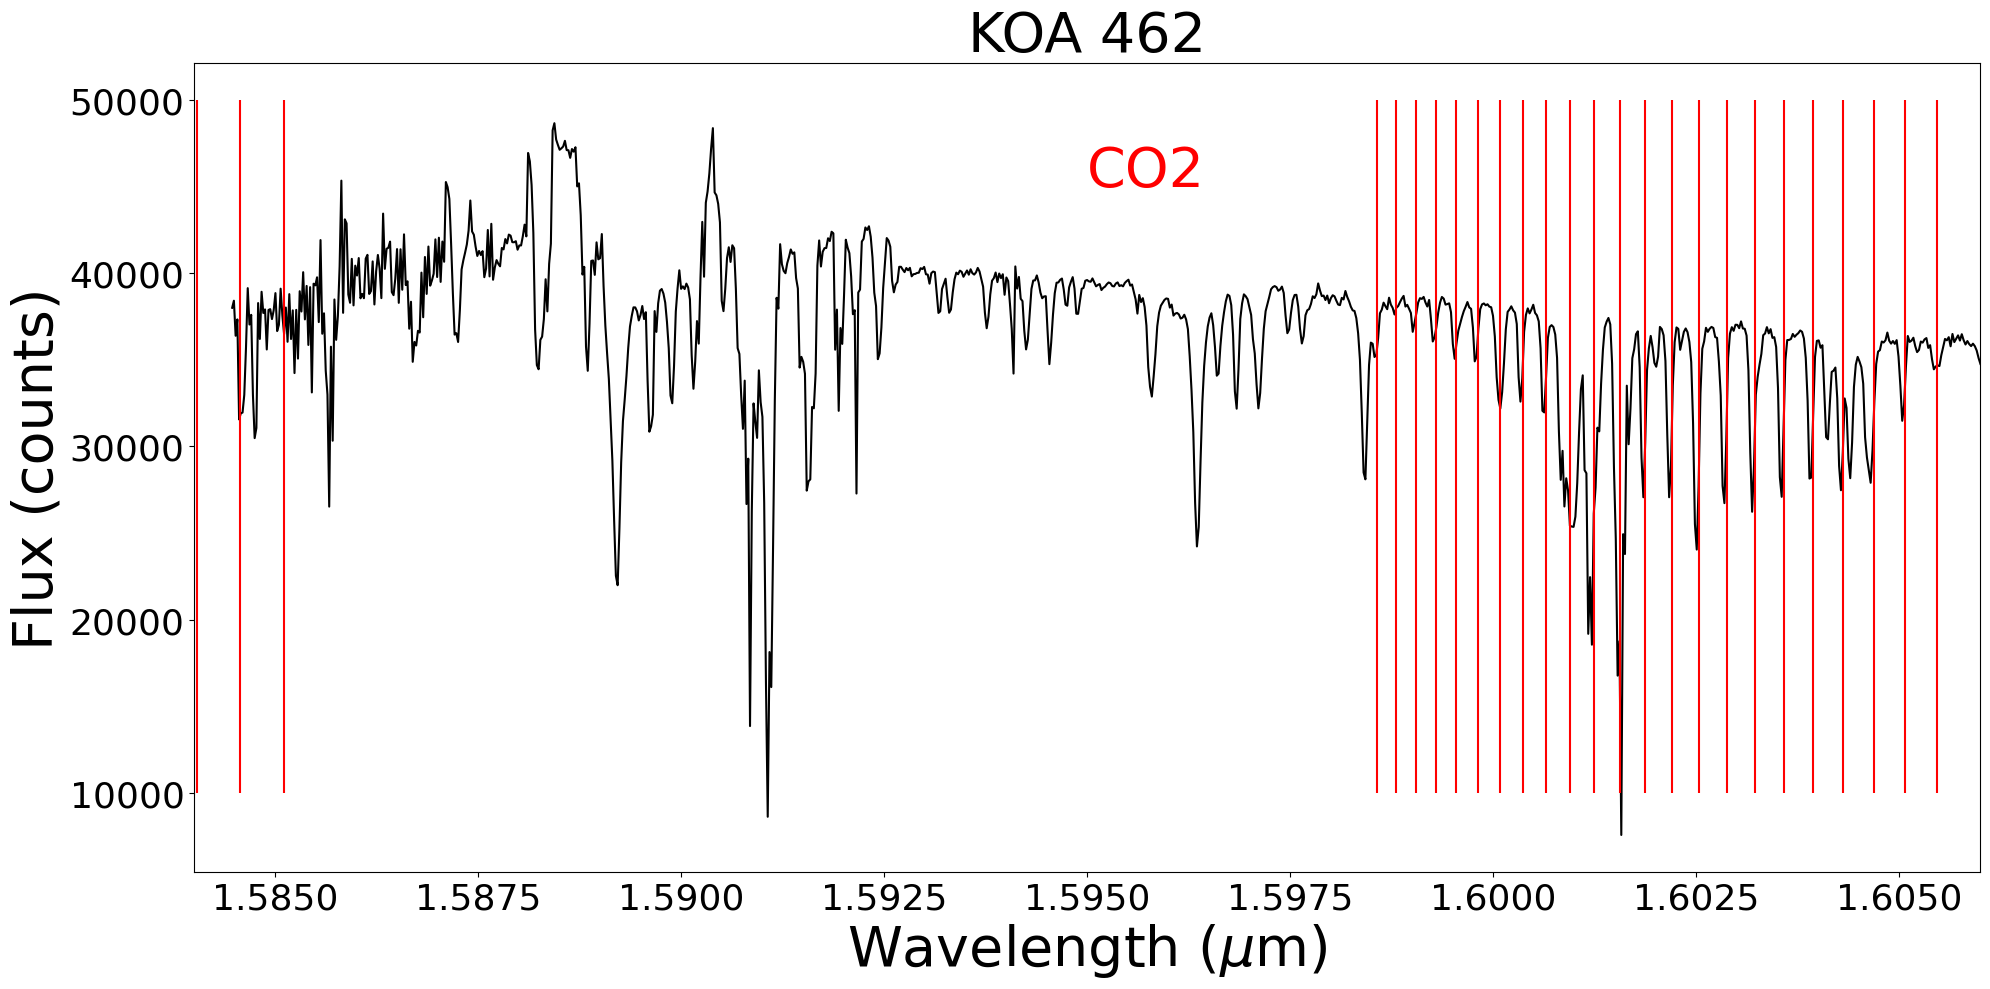

In [536]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(wavelength, flux, color = 'k', label = 'data') # Plotting wavelength vs. flux and coloring the data

plt.xlim([1.584, 1.606]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['wavelength'], ymin=10000, ymax=50000, color='r', label = 'CO2') # Plotting vertical lines at CO2 absorption features
plt.text(1.595, 45000., 'CO2', fontsize=fs, color='r') # labelling CO2 red and applying fontsize

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 462', fontsize = fs) # Giving the plot a title and applying fontsize

plt.tight_layout()
plt.savefig('figs/KOA_462_CO2.pdf') # Saving the plot
plt.show() # Show the plot

In [537]:
# KOA_104087
fits_file_b = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_104087/NIRSPEC/extracted/fitstbl/flux/NS.20000325.42919_49_flux_tbl.fits.gz')

data_class_b = fits_file_b[1] # Get the [1]th element of fits_file
data_b = data_class_b.data # Get the data from data_class

b = data_b['wave (A)'] # Get the wavelength column
r = data_b['flux (cnts)'] # Get the flux column
b = b / 10000 # Convert the wavelength from Angstroms to microns

In [538]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['b'] = 1/co2['nu']
co2['b'] = co2['b'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

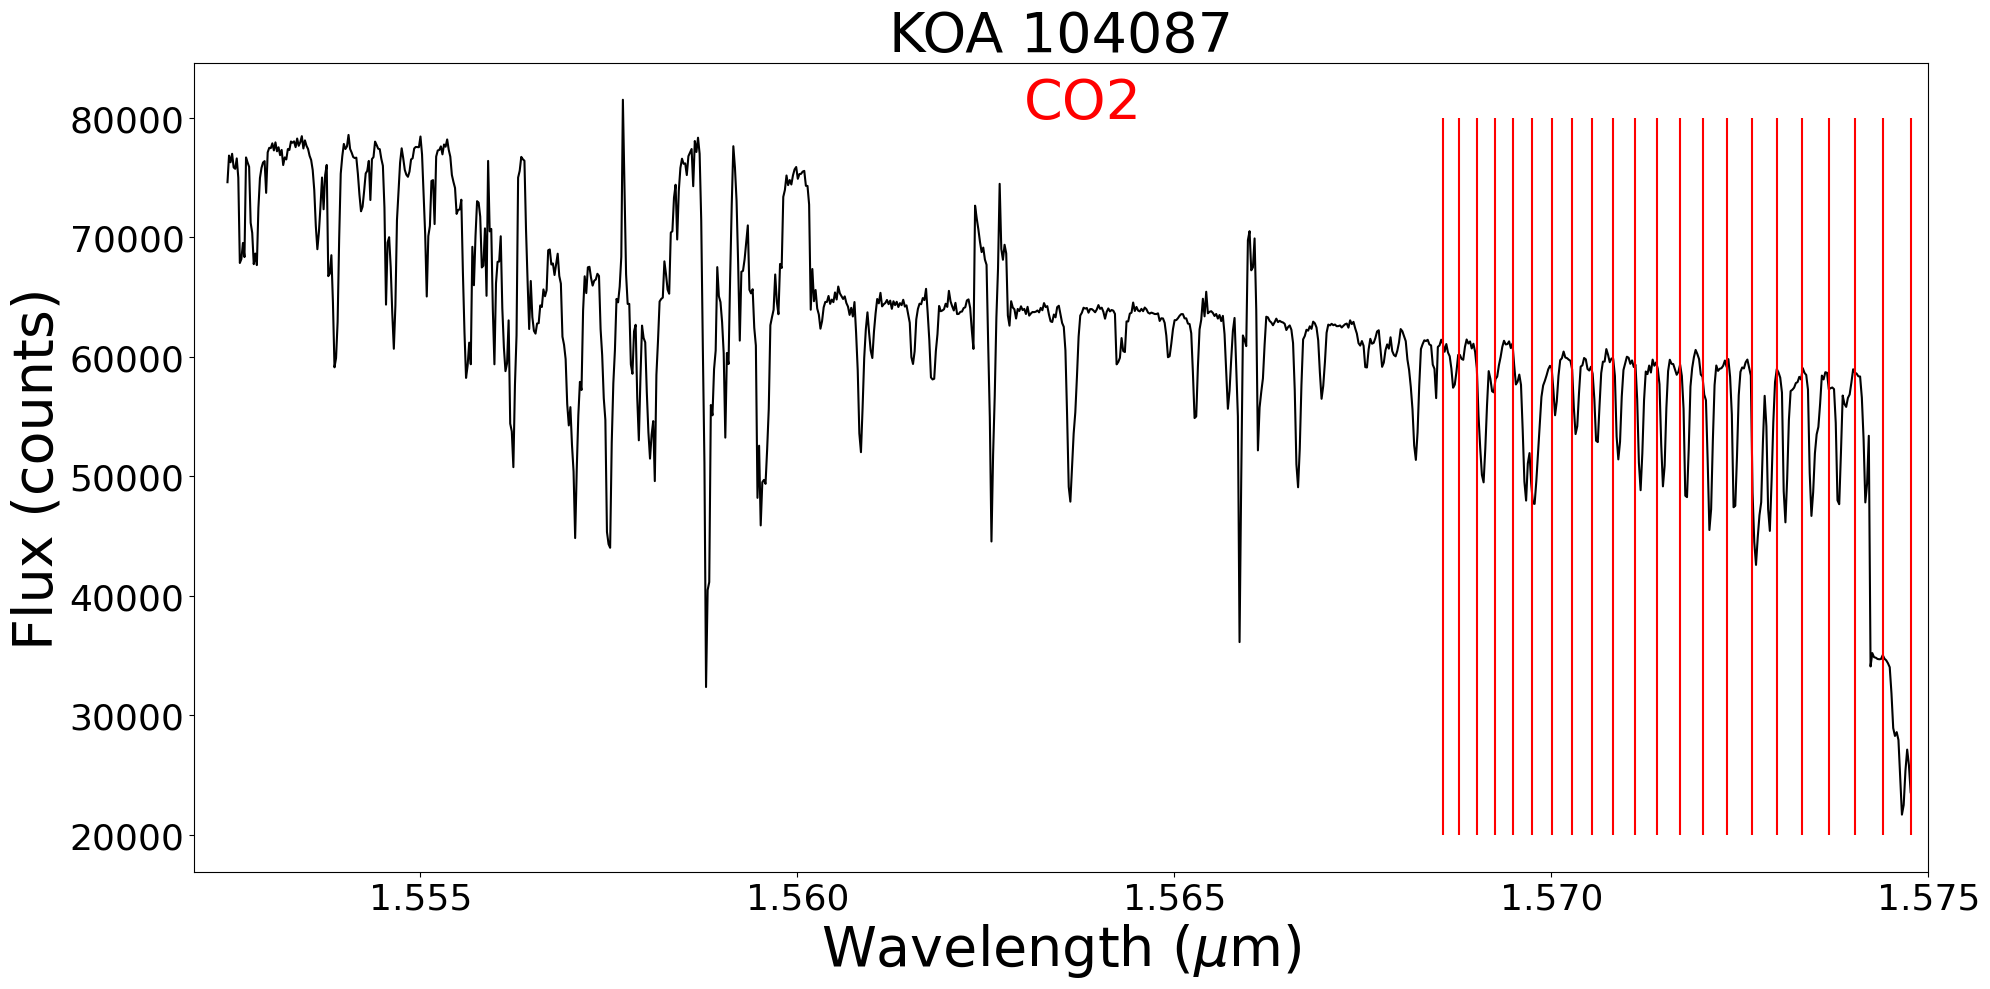

In [539]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(b, r, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.552, 1.575]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['b'], ymin = 20000, ymax = 80000, color = 'r', label = 'CO2')
plt.text(1.563, 80000,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 104087', fontsize = fs) # Giving the plot a title and applying fontsize

plt.tight_layout()
plt.savefig('figs/KOA_104087_CO2.pdf') # Saving the plot
plt.show()

In [540]:
# KOA_109549
fits_file_c = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_109549/NIRSPEC/extracted/fitstbl/flux/NS.20000325.45382_48_flux_tbl.fits.gz')

data_class_c = fits_file_c[1] # Get the [1]th element of fits_file
data_c = data_class_c.data # Get the data from data_class

c = data_c['wave (A)'] # Get the wavelength column
s = data_c['flux (cnts)'] # Get the flux column
c = c / 10000 # Convert the wavelength from Angstroms to microns

In [541]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['c'] = 1/co2['nu']
co2['c'] = co2['c'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

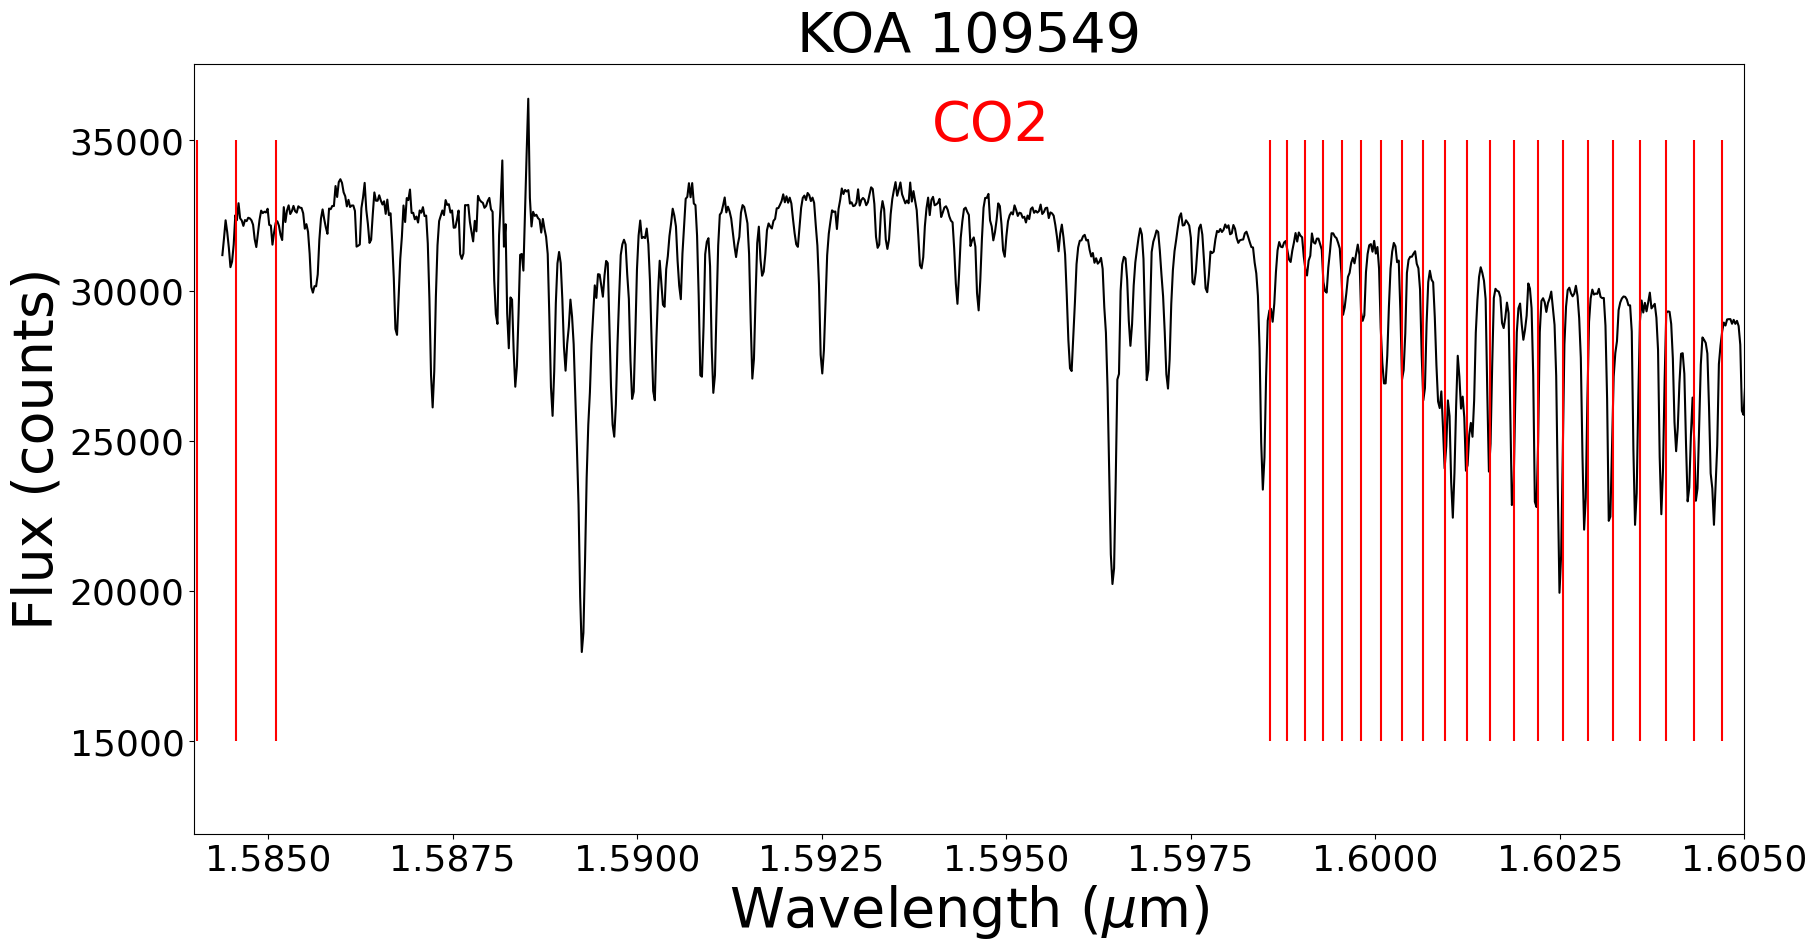

In [542]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(c, s, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.584, 1.605]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['c'], ymin = 15000, ymax = 35000, color = 'r', label = 'CO2')
plt.text(1.594, 35000,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 109549', fontsize = fs) # Giving the plot a title and applying fontsize

plt.show() # Show the plot

In [543]:
# KOA_115150
fits_file_d = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_115150/NIRSPEC/extracted/fitstbl/flux/NS.20000325.45429_48_flux_tbl.fits.gz')

data_class_d = fits_file_d[1] # Get the [1]th element of fits_file
data_d = data_class_d.data # Get the data from data_class

d = data_d['wave (A)'] # Get the wavelength column
t = data_d['flux (cnts)'] # Get the flux column
d = d / 10000 # Convert the wavelength from Angstroms to microns 

In [544]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['d'] = 1/co2['nu']
co2['d'] = co2['d'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

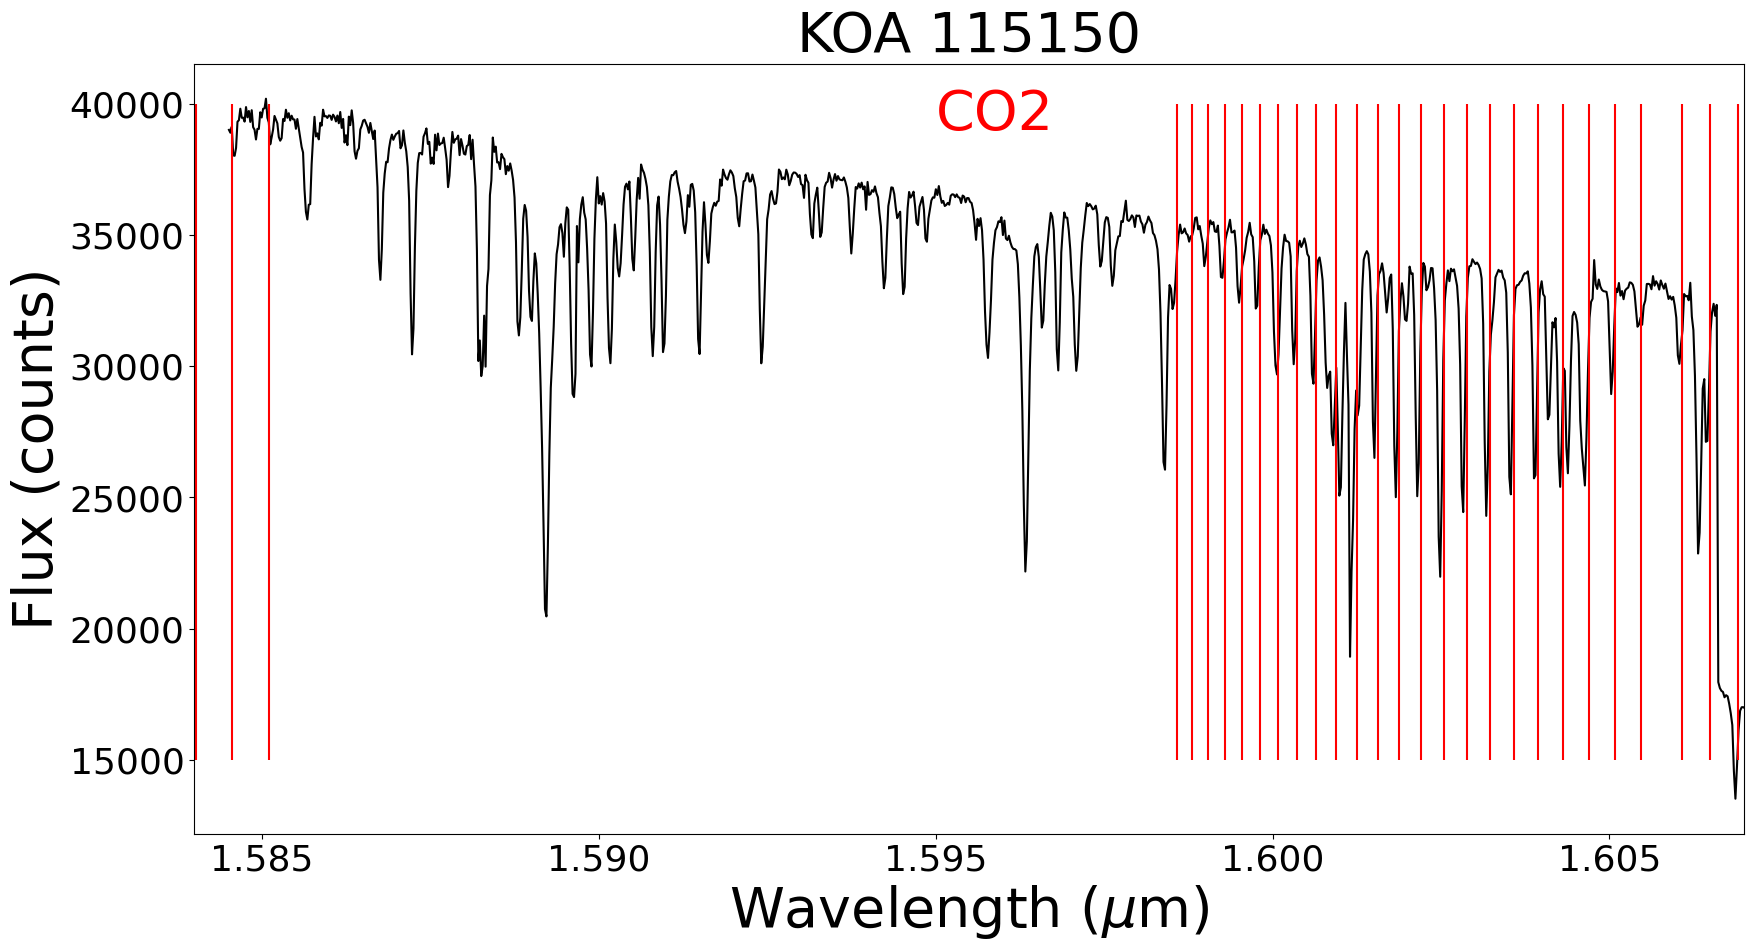

In [545]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(d, t, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.584, 1.607]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['d'], ymin = 15000, ymax = 40000, color = 'r', label = 'CO2')
plt.text(1.595, 39000,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 115150', fontsize = fs) # Giving the plot a title and applying fontsize

plt.show() # Show the plot

In [546]:
# KOA_115835
fits_file_e = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_115835/NIRSPEC/extracted/fitstbl/flux/NS.20000326.42541_48_flux_tbl.fits.gz')

data_class_e = fits_file_e[1] # Get the [1]th element of fits_file
data_e = data_class_e.data # Get the data from data_class

e = data_e['wave (A)'] # Get the wavelength column
u = data_e['flux (cnts)'] # Get the flux column
e = e / 10000 # Convert the wavelength from Angstroms to microns 

In [547]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['e'] = 1/co2['nu']
co2['e'] = co2['e'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

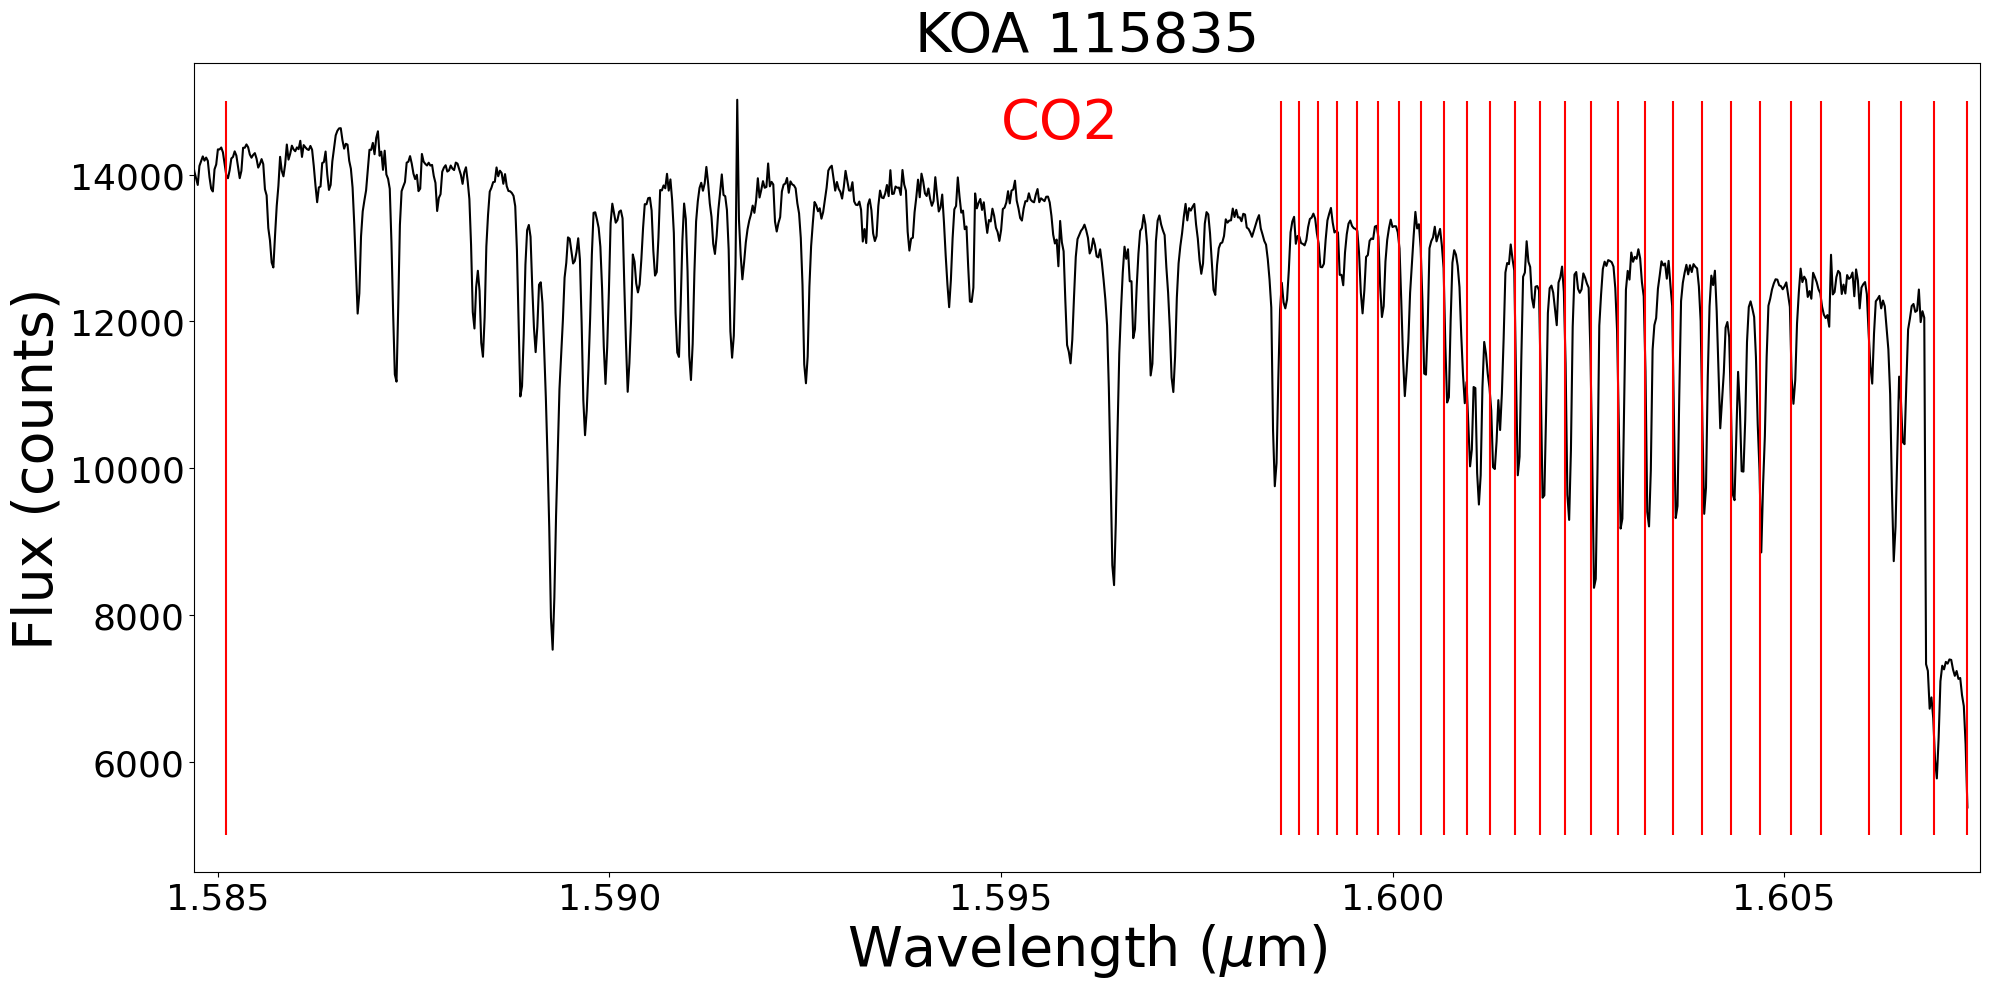

In [548]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(e, u, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.5847, 1.6075]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['e'], ymin = 5000, ymax = 15000, color = 'r', label = 'CO2')
plt.text(1.595, 14500,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 115835', fontsize = fs) # Giving the plot a title and applying fontsize

plt.tight_layout()
plt.savefig('figs/KOA_115835_CO2.pdf') # Saving the plot
plt.show()

In [549]:
# KOA_116684
fits_file_f = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_116684/NIRSPEC/extracted/fitstbl/flux/NS.20000328.42246_48_flux_tbl.fits.gz')

data_class_f = fits_file_f[1] # Get the [1]th element of fits_file
data_f = data_class_f.data # Get the data from data_class

f = data_f['wave (A)'] # Get the wavelength column
v = data_f['flux (cnts)'] # Get the flux column
f = f / 10000 # Convert the wavelength from Angstroms to microns 

In [550]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['f'] = 1/co2['nu']
co2['f'] = co2['f'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

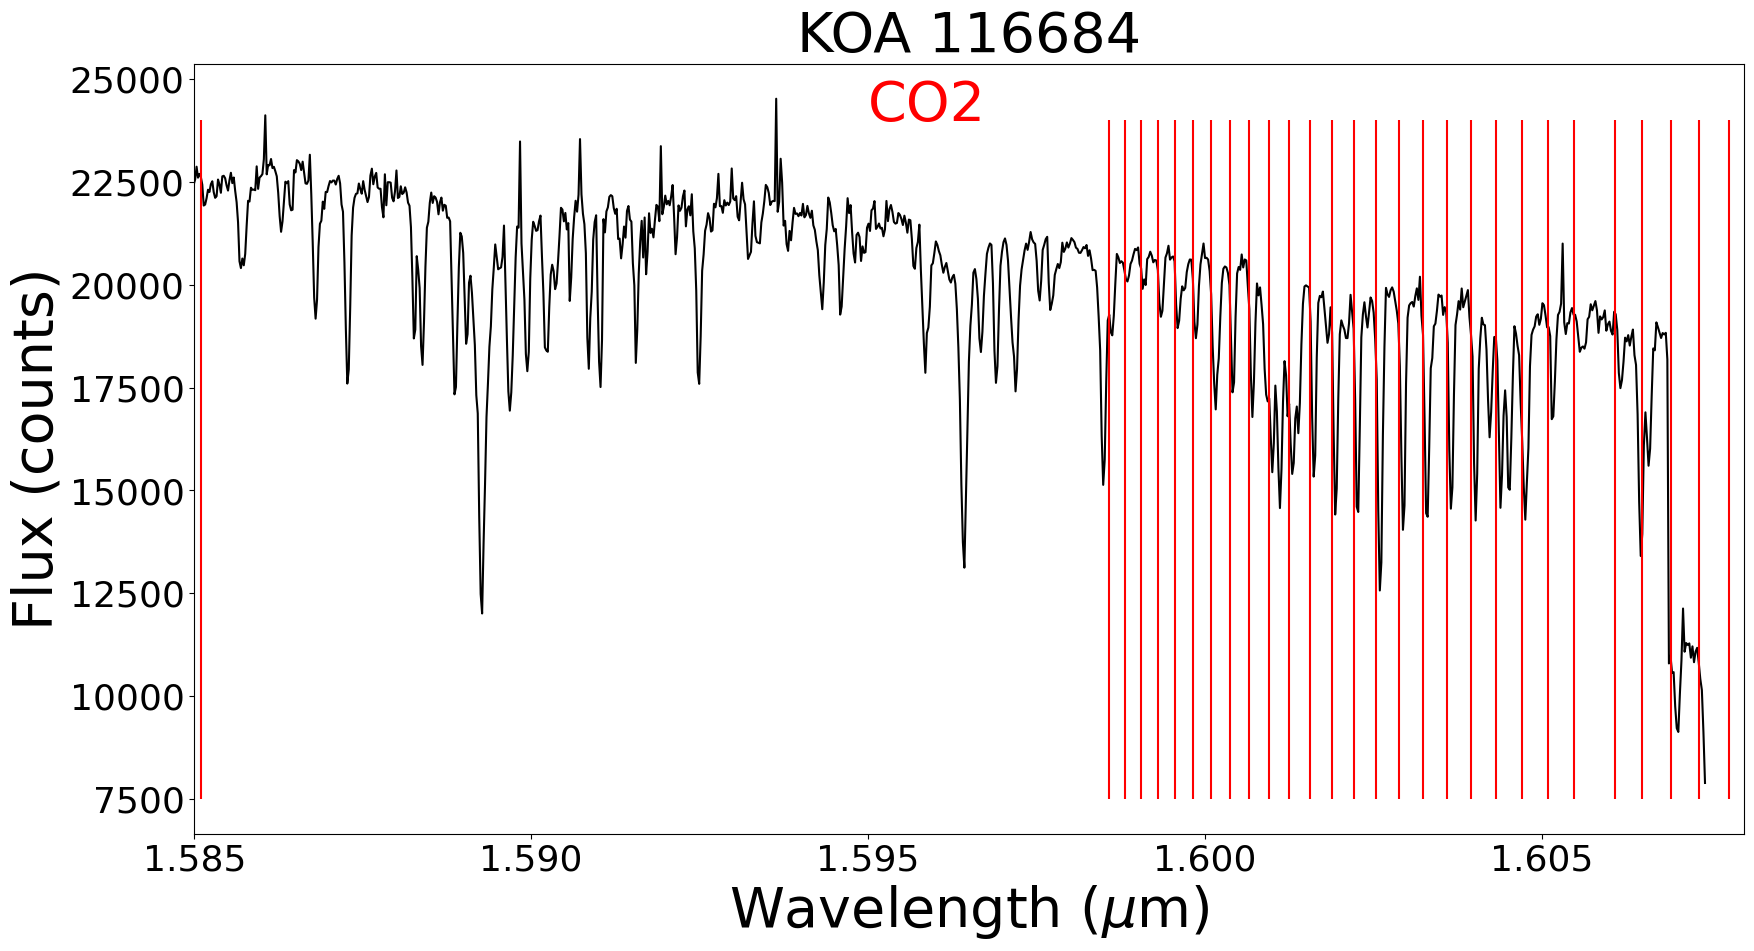

In [551]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(f, v, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.585, 1.608]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['f'], ymin = 7500, ymax = 24000, color = 'r', label = 'CO2')
plt.text(1.595, 24000,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 116684', fontsize = fs) # Giving the plot a title and applying fontsize

plt.show() # Show the plot 

In [552]:
# KOA_117338
fits_file_g = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_117338/NIRSPEC/extracted/fitstbl/flux/NS.20000328.42354_48_flux_tbl.fits.gz')

data_class_g = fits_file_g[1] # Get the [1]th element of fits_file
data_g = data_class_g.data # Get the data from data_class

g = data_g['wave (A)'] # Get the wavelength column
w = data_g['flux (cnts)'] # Get the flux column
g = g / 10000 # Convert the wavelength from Angstroms to microns 

In [553]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['g'] = 1/co2['nu']
co2['g'] = co2['g'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

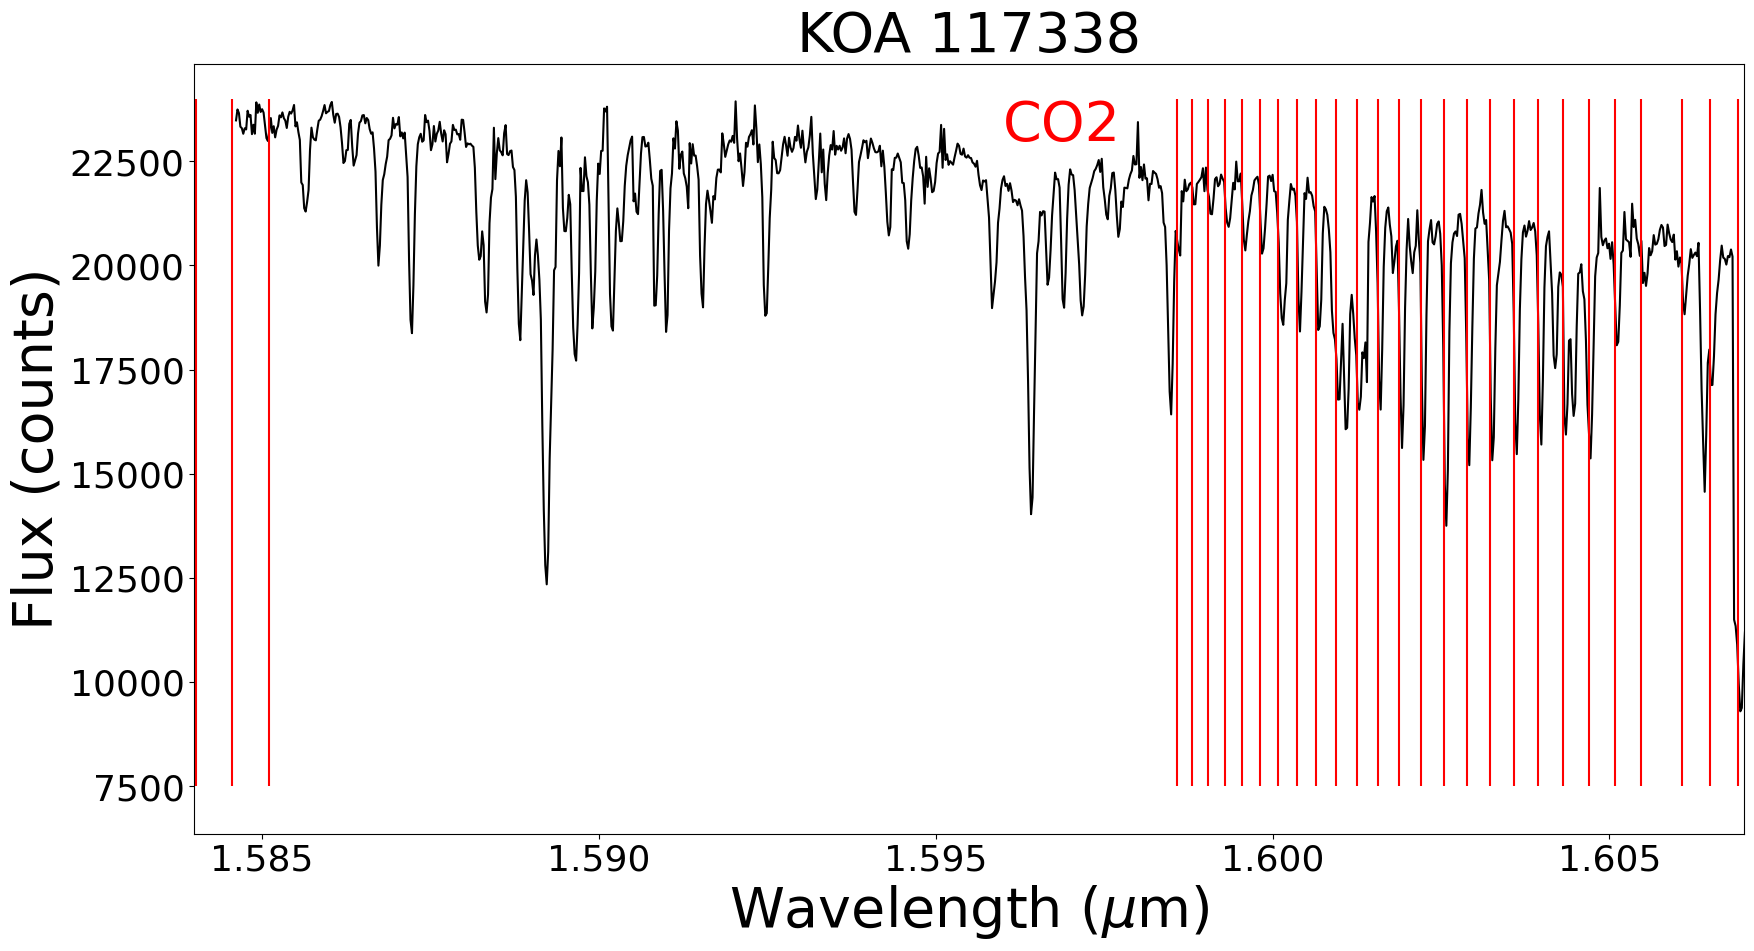

In [554]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(g, w, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.584, 1.607]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['g'], ymin = 7500, ymax = 24000, color = 'r', label = 'CO2')
plt.text(1.596, 23000,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 117338', fontsize = fs) # Giving the plot a title and applying fontsize

plt.show() # Show the plot 

In [555]:
# KOA_118044
fits_file_h = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_118044/NIRSPEC/extracted/fitstbl/flux/NS.20000328.42449_48_flux_tbl.fits.gz')

data_class_h = fits_file_h[1] # Get the [1]th element of fits_file
data_h = data_class_h.data # Get the data from data_class

h = data_h['wave (A)'] # Get the wavelength column
x = data_h['flux (cnts)'] # Get the flux column
h = h / 10000 # Convert the wavelength from Angstroms to microns 

In [556]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['h'] = 1/co2['nu']
co2['h'] = co2['h'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

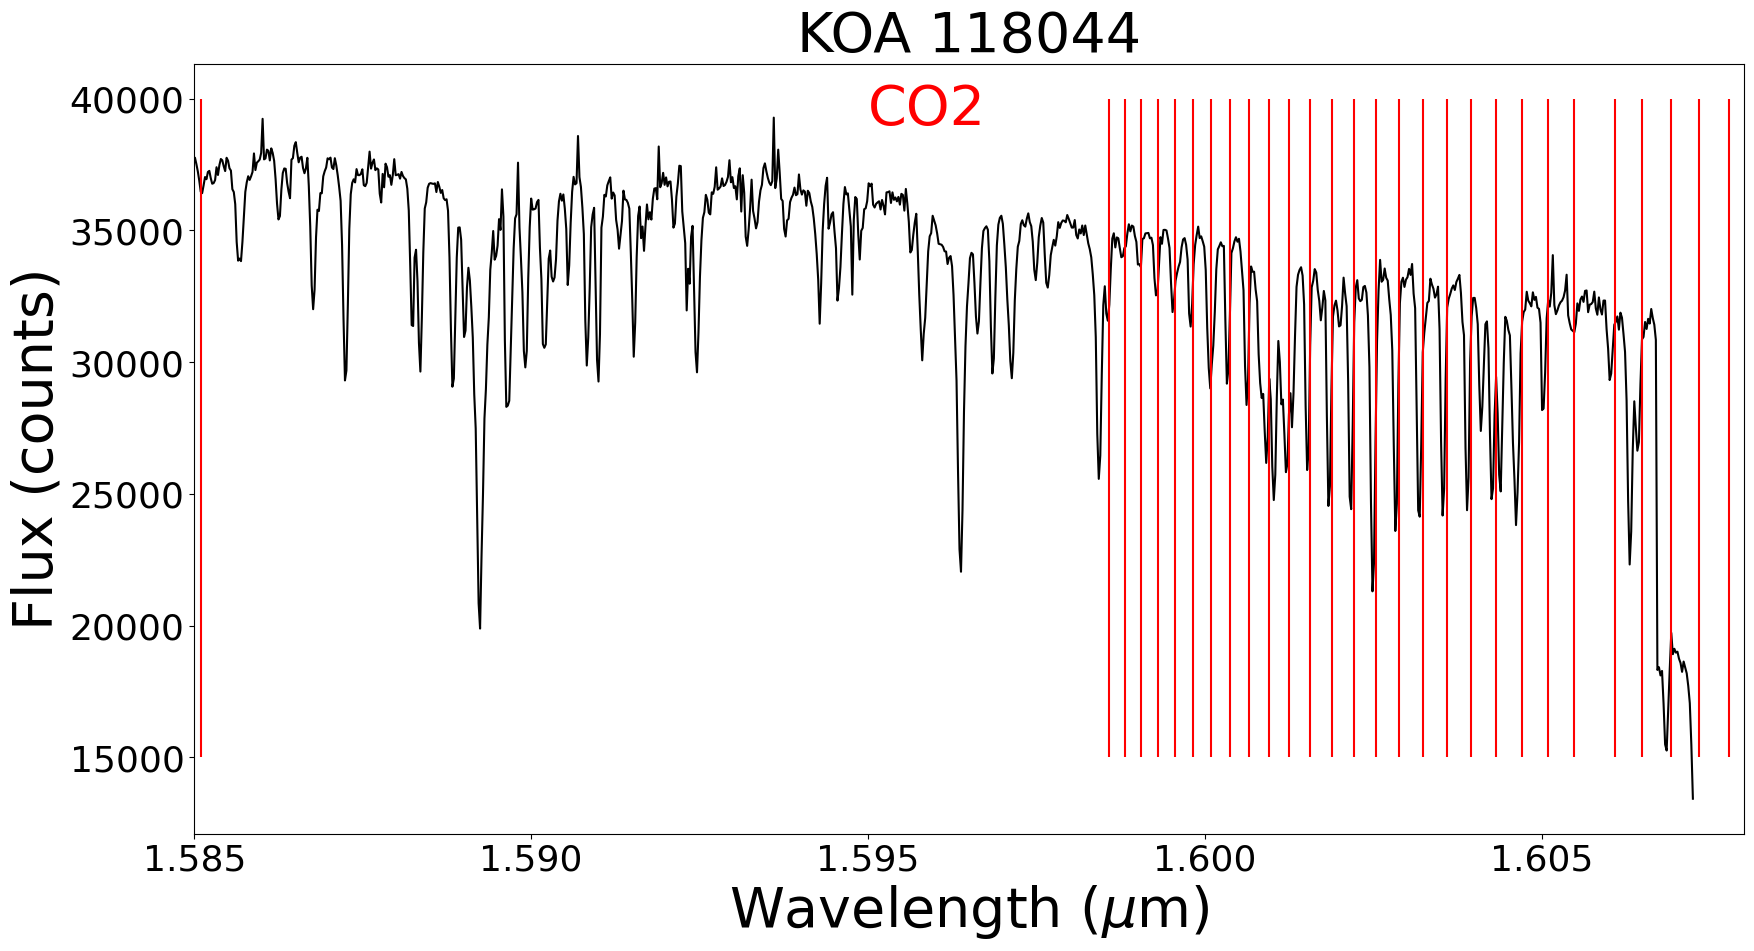

In [557]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(h, x, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.585, 1.608]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['h'], ymin = 15000, ymax = 40000, color = 'r', label = 'CO2')
plt.text(1.595, 39000,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 118044', fontsize = fs) # Giving the plot a title and applying fontsize

plt.show() # Show the plot 

In [558]:
# KOA_118924
fits_file_i = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_118924/NIRSPEC/extracted/fitstbl/flux/NS.20000328.43045_48_flux_tbl.fits.gz')

data_class_i = fits_file_i[1] # Get the [1]th element of fits_file
data_i = data_class_i.data # Get the data from data_class

i = data_i['wave (A)'] # Get the wavelength column
y = data_i['flux (cnts)'] # Get the flux column
i = i / 10000 # Convert the wavelength from Angstroms to microns 

In [559]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['i'] = 1/co2['nu']
co2['i'] = co2['i'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

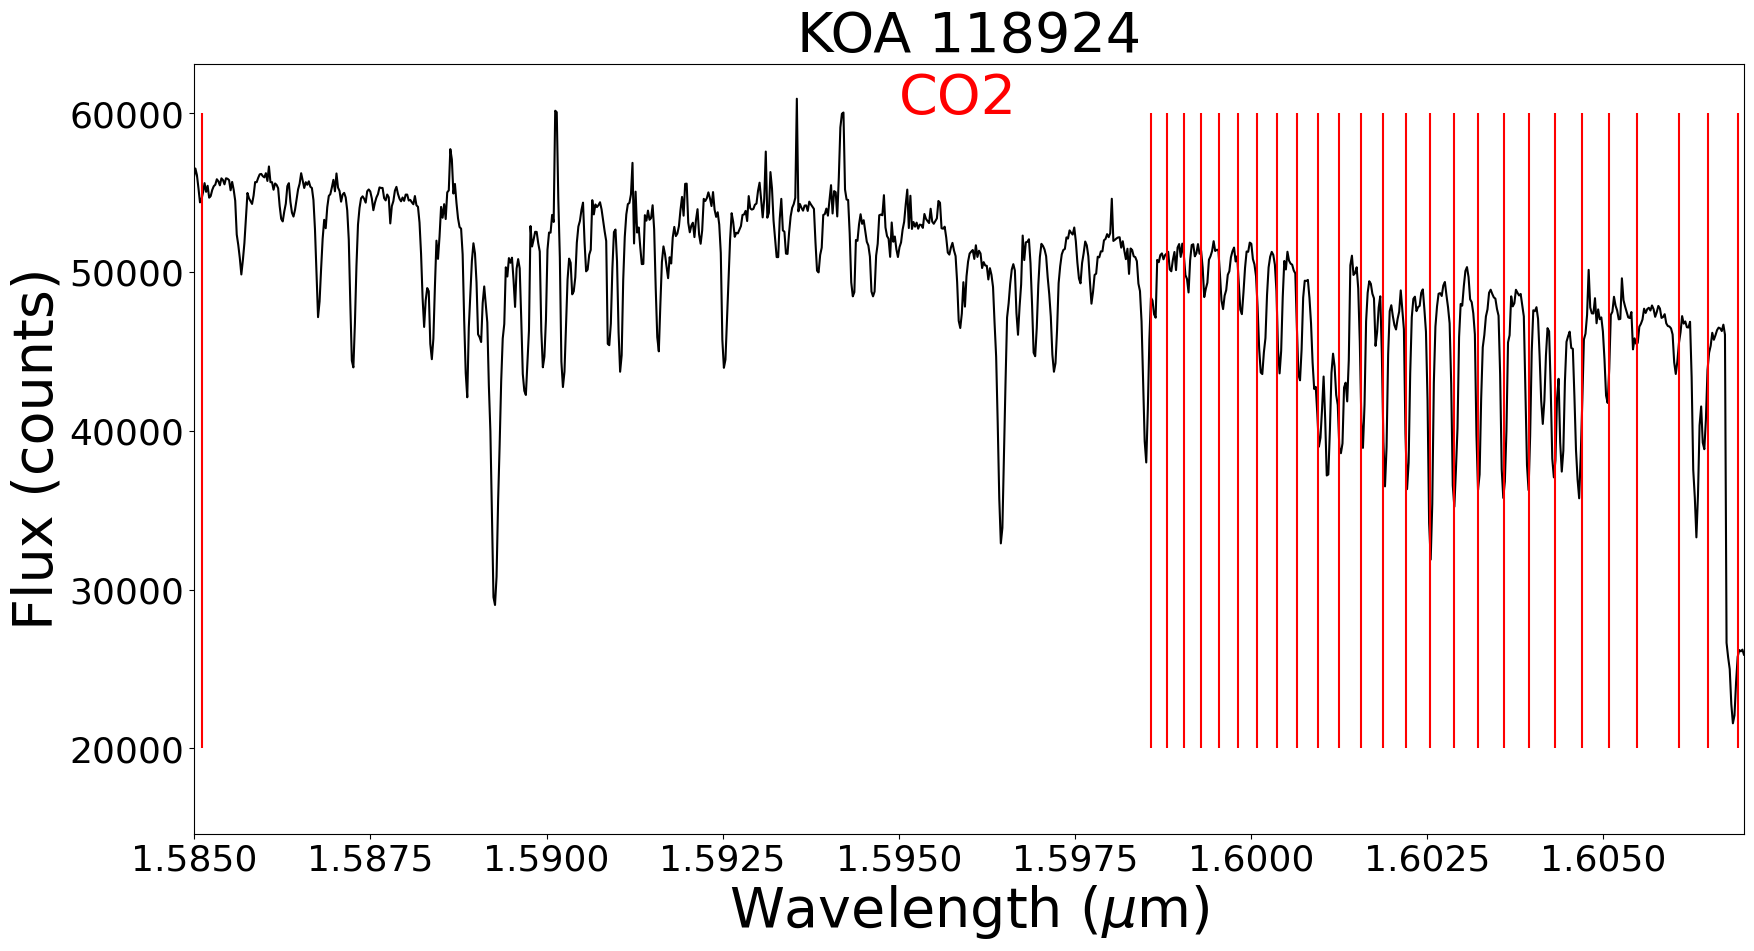

In [560]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(i, y, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.585, 1.607]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['i'], ymin = 20000, ymax = 60000, color = 'r', label = 'CO2')
plt.text(1.595, 60000,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 118924', fontsize = fs) # Giving the plot a title and applying fontsize

plt.show() # Show the plot 

In [561]:
# KOA_119438
fits_file_j = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_119438/NIRSPEC/extracted/fitstbl/flux/NS.20000328.48623_48_flux_tbl.fits.gz')

data_class_j = fits_file_j[1] # Get the [1]th element of fits_file
data_j = data_class_j.data # Get the data from data_class

j = data_j['wave (A)'] # Get the wavelength column
z = data_j['flux (cnts)'] # Get the flux column
j = j / 10000 # Convert the wavelength from Angstroms to microns 

In [562]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['j'] = 1/co2['nu']
co2['j'] = co2['j'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

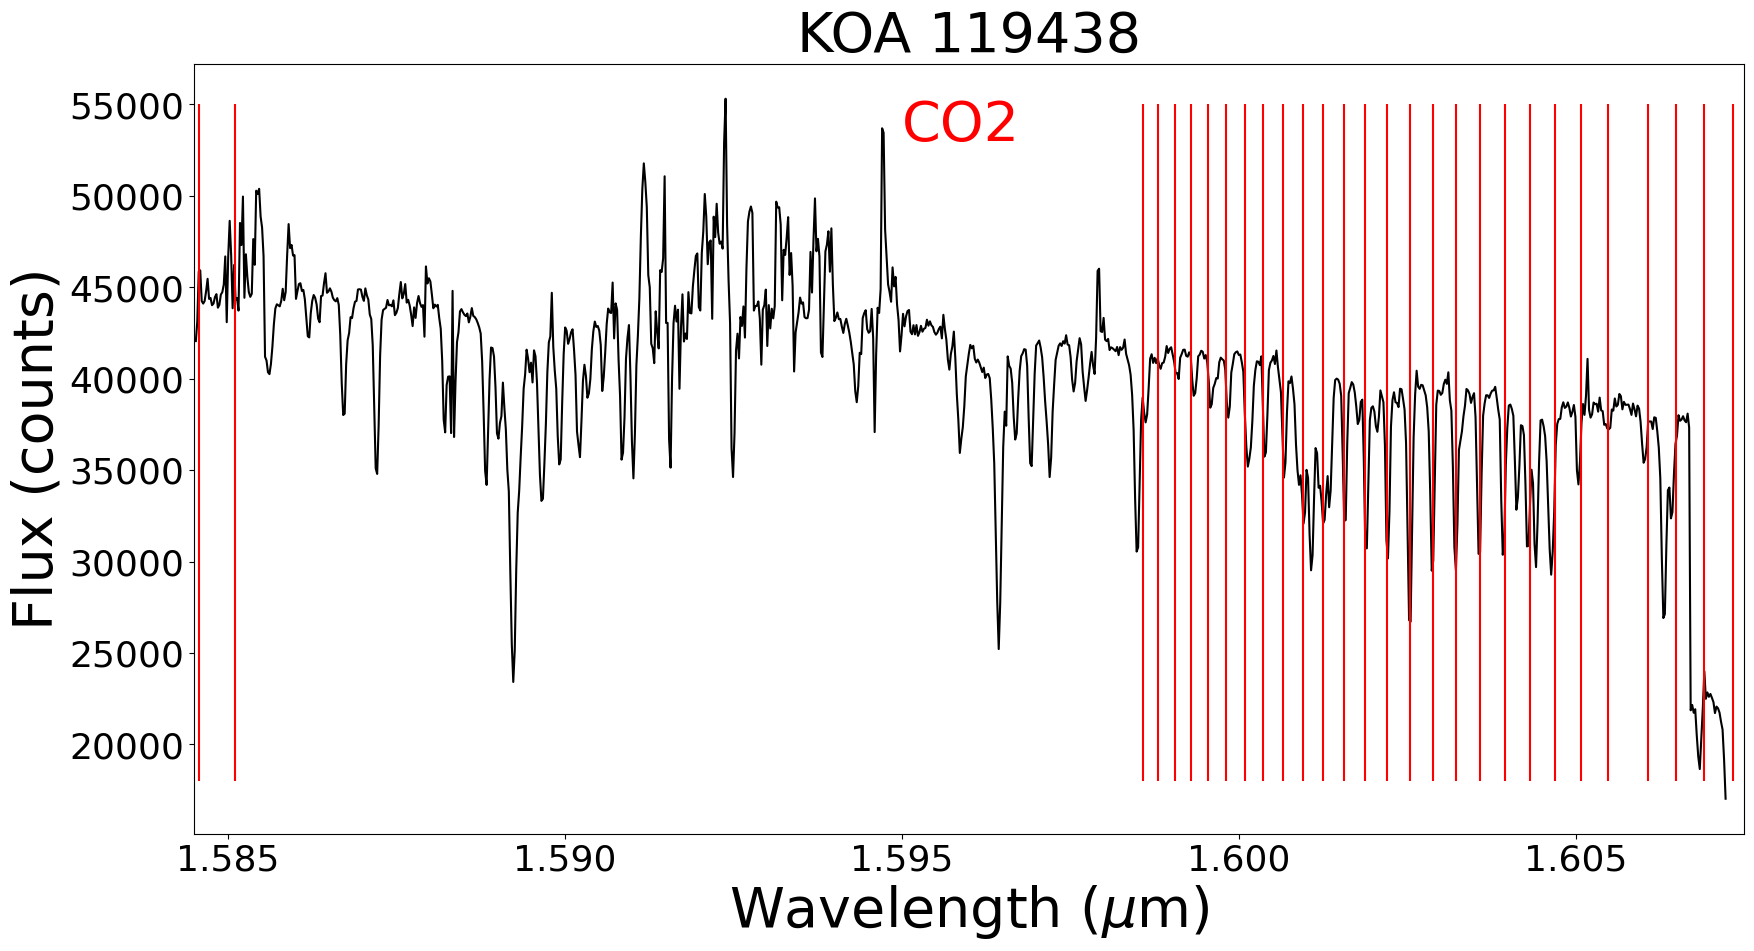

In [563]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(j, z, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.5845, 1.6075]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['j'], ymin = 18000, ymax = 55000, color = 'r', label = 'CO2')
plt.text(1.595, 53000,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 119438', fontsize = fs) # Giving the plot a title and applying fontsize

plt.show() # Show the plot 

In [564]:
# KOA_121026
fits_file_k = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_121026/NIRSPEC/extracted/fitstbl/flux/NS.20150531.20298_48_flux_tbl.fits.gz')

data_class_k = fits_file_k[1] # Get the [1]th element of fits_file
data_k = data_class_k.data # Get the data from data_class

k = data_k['wave (A)'] # Get the wavelength column
ab = data_k['flux (cnts)'] # Get the flux column
k = k / 10000 # Convert the wavelength from Angstroms to microns 

In [565]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['k'] = 1/co2['nu']
co2['k'] = co2['k'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

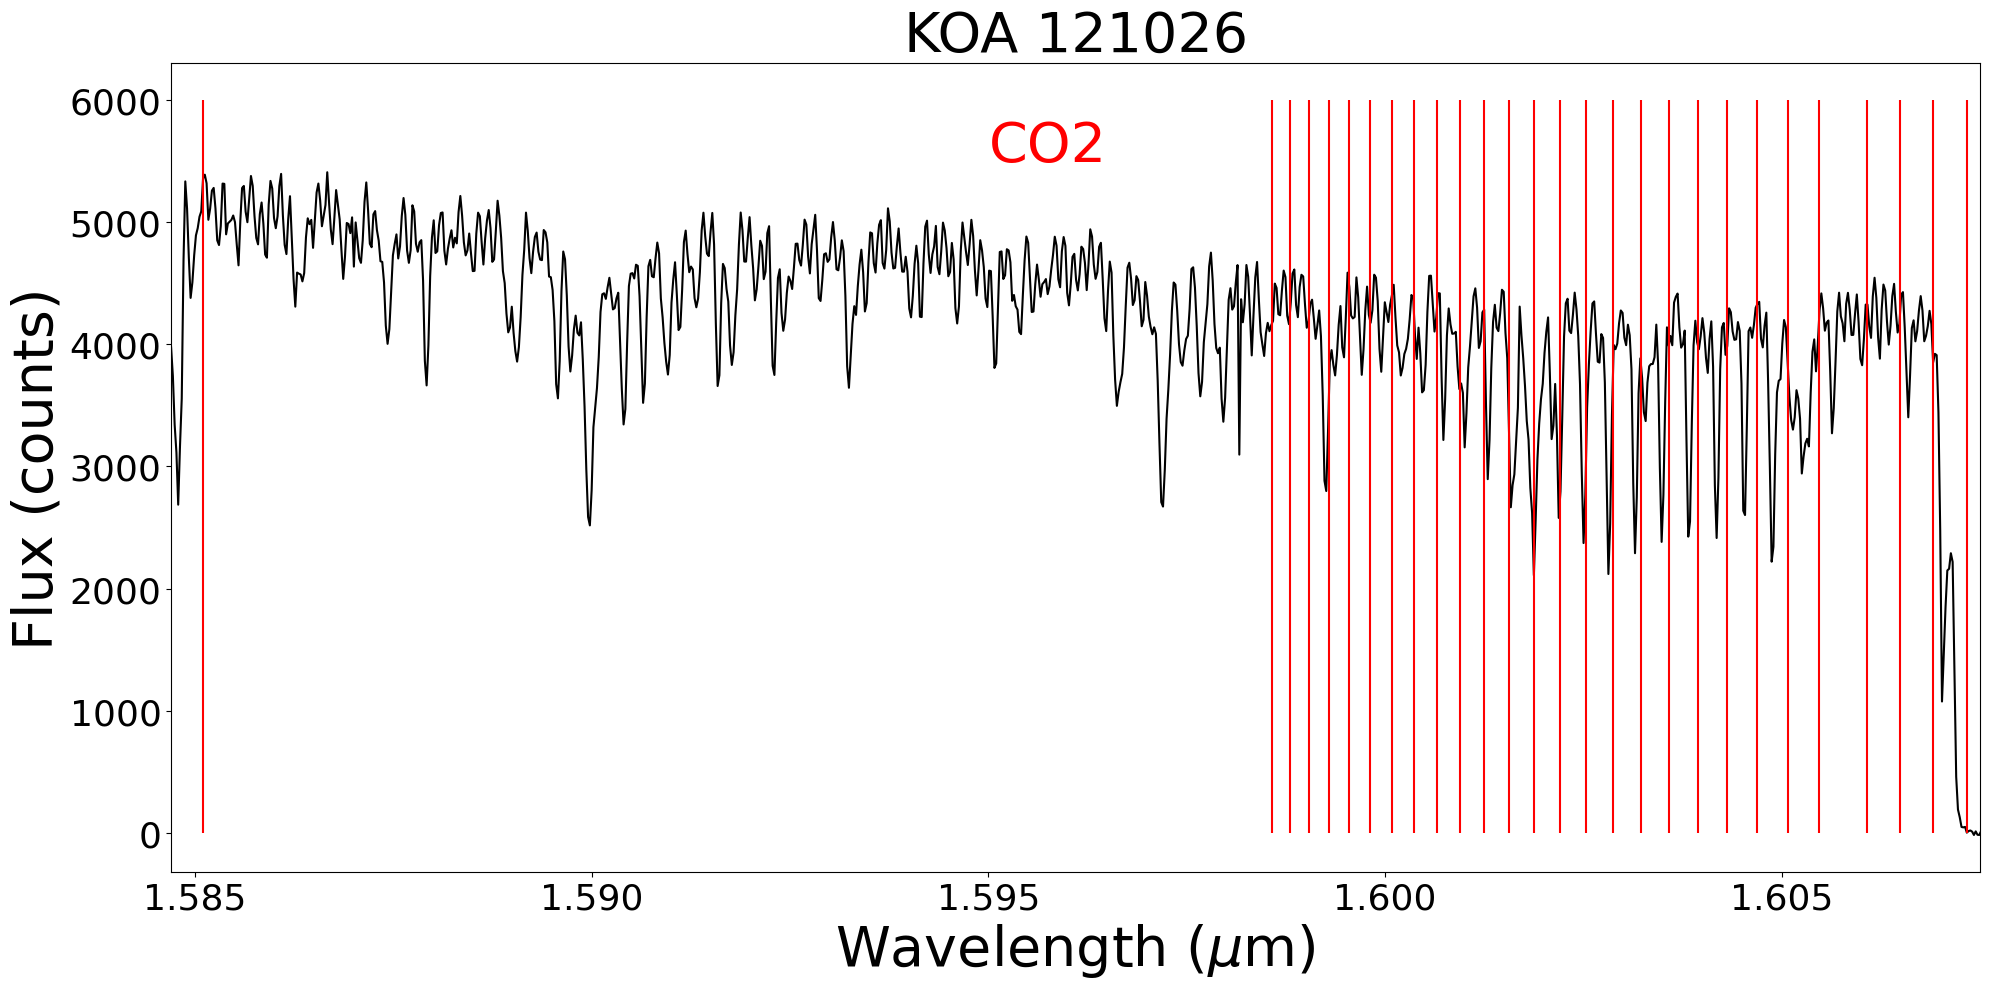

In [566]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(k, ab, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.5847, 1.6075]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['k'], ymin = 0, ymax = 6000, color = 'r', label = 'CO2')
plt.text(1.595, 5500,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 121026', fontsize = fs) # Giving the plot a title and applying fontsize

plt.tight_layout()
plt.savefig('figs/KOA_121026_CO2.pdf') # Saving the plot
plt.show()

In [567]:
# KOA_127558
fits_file_l = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_127558/NIRSPEC/extracted/fitstbl/flux/NS.20150531.20033_48_flux_tbl.fits.gz')

data_class_l = fits_file_l[1] # Get the [1]th element of fits_file
data_l = data_class_l.data # Get the data from data_class

l = data_l['wave (A)'] # Get the wavelength column
cd = data_l['flux (cnts)'] # Get the flux column
l = l / 10000 # Convert the wavelength from Angstroms to microns 

In [568]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['l'] = 1/co2['nu']
co2['l'] = co2['l'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

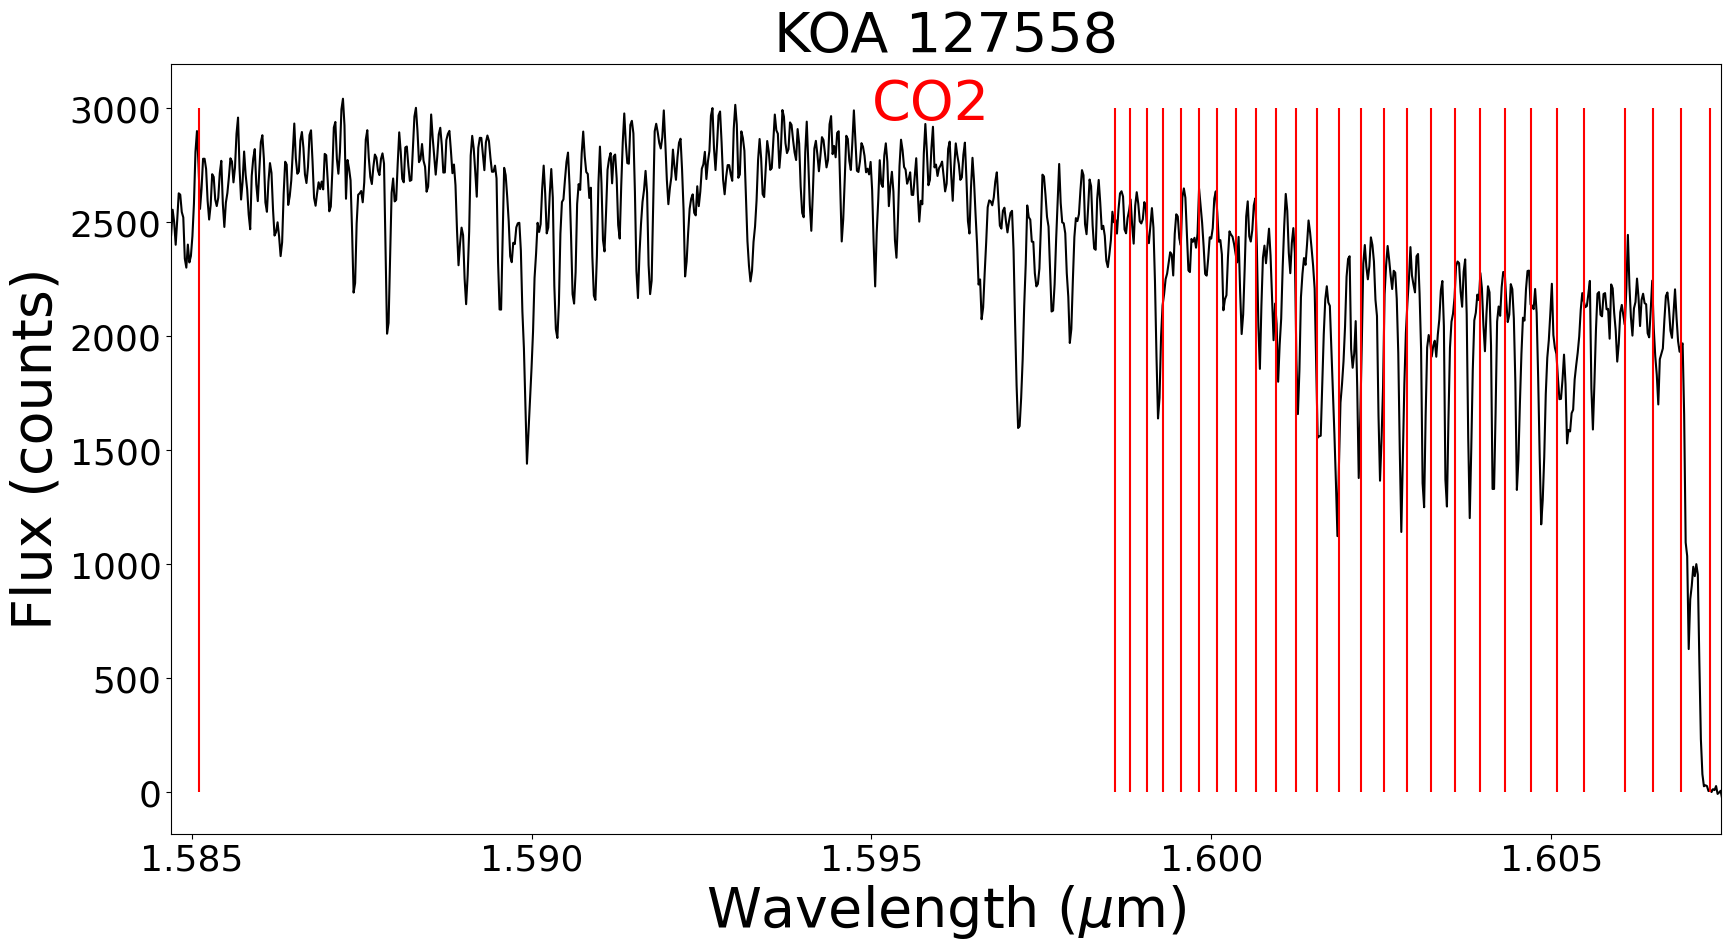

In [569]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(l, cd, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.5847, 1.6075]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['l'], ymin = 0, ymax = 3000, color = 'r', label = 'CO2')
plt.text(1.595, 2950,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 127558', fontsize = fs) # Giving the plot a title and applying fontsize

plt.show() # Show the plot

In [570]:
# KOA_128234
fits_file_m = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_128234/NIRSPEC/extracted/fitstbl/flux/NS.20150530.21684_48_flux_tbl.fits.gz')

data_class_m = fits_file_m[1] # Get the [1]th element of fits_file
data_m = data_class_m.data # Get the data from data_class

m = data_m['wave (A)'] # Get the wavelength column
ef = data_m['flux (cnts)'] # Get the flux column
m = m / 10000 # Convert the wavelength from Angstroms to microns 

In [571]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['m'] = 1/co2['nu']
co2['m'] = co2['m'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

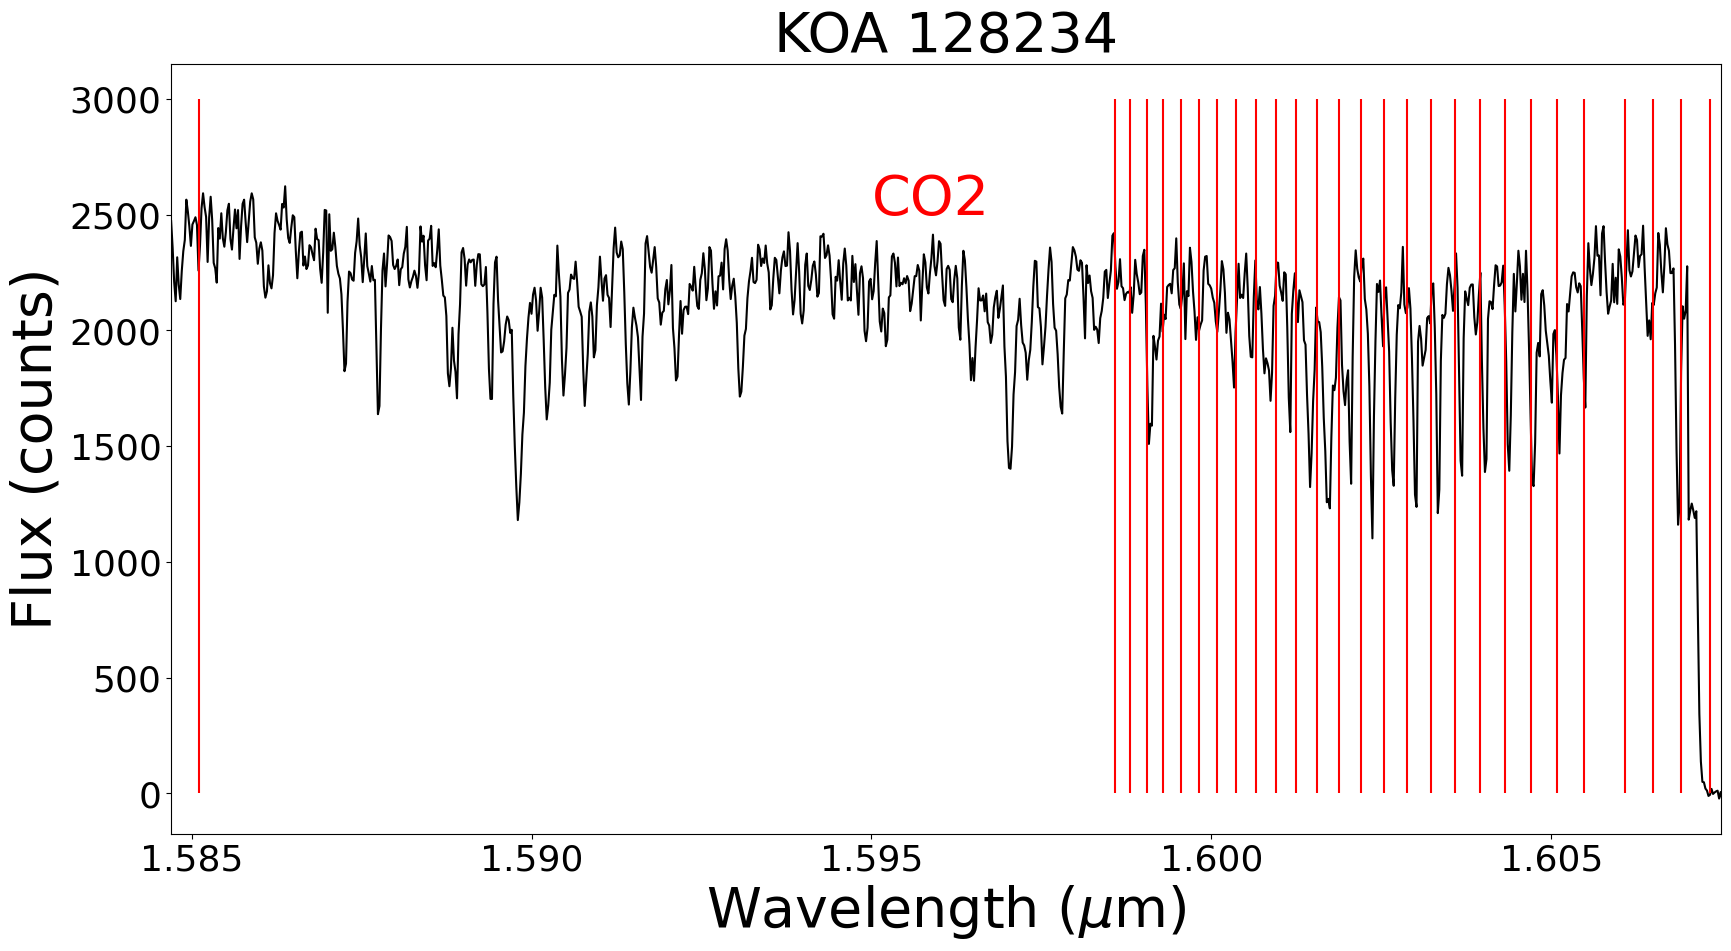

In [572]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(m, ef, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.5847, 1.6075]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['m'], ymin = 0, ymax = 3000, color = 'r', label = 'CO2')
plt.text(1.595, 2500,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 128234', fontsize = fs) # Giving the plot a title and applying fontsize

plt.show() # Show the plot

In [573]:
# KOA_128884
fits_file_n = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_128884/NIRSPEC/extracted/fitstbl/flux/NS.20150530.21571_48_flux_tbl.fits.gz')

data_class_n = fits_file_n[1] # Get the [1]th element of fits_file
data_n = data_class_n.data # Get the data from data_class

n = data_n['wave (A)'] # Get the wavelength column
gh = data_n['flux (cnts)'] # Get the flux column
n = n / 10000 # Convert the wavelength from Angstroms to microns 

In [574]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['n'] = 1/co2['nu']
co2['n'] = co2['n'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

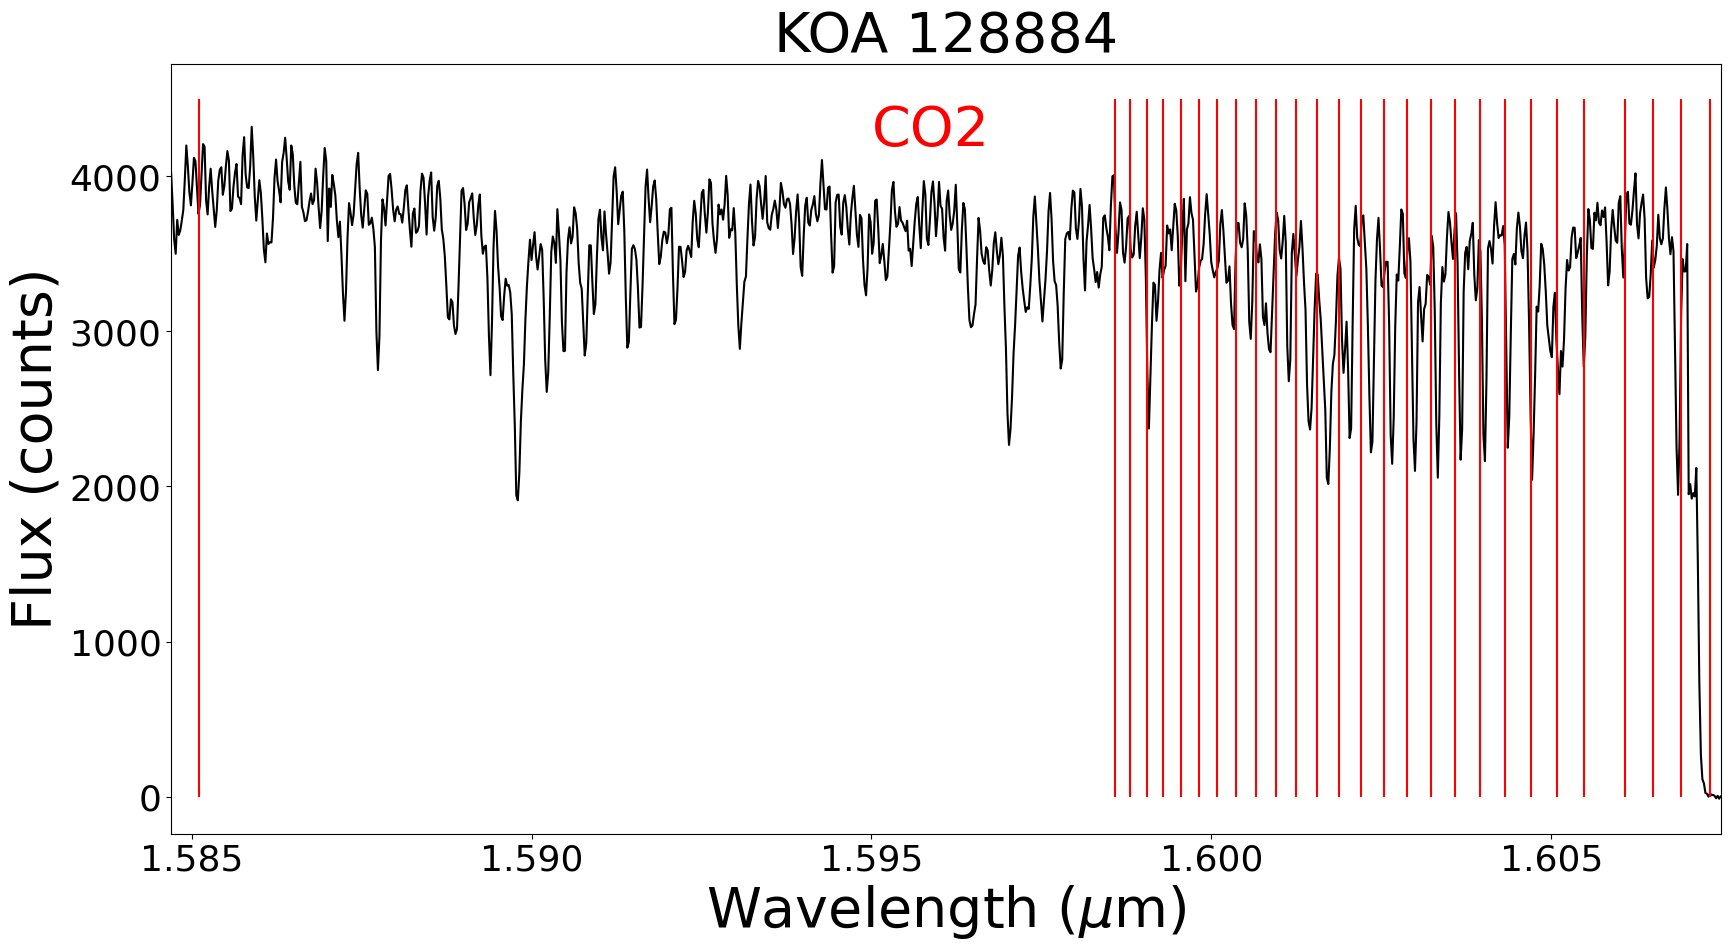

In [575]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(n, gh, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.5847, 1.6075]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['n'], ymin = 0, ymax = 4500, color = 'r', label = 'CO2')
plt.text(1.595, 4200,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 128884', fontsize = fs) # Giving the plot a title and applying fontsize

plt.show() # Show the plot

In [576]:
# KOA_129898
fits_file_o = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_129898/NIRSPEC/extracted/fitstbl/flux/NS.20150530.21300_48_flux_tbl.fits.gz')

data_class_o = fits_file_o[1] # Get the [1]th element of fits_file
data_o = data_class_o.data # Get the data from data_class

o = data_o['wave (A)'] # Get the wavelength column
ij = data_o['flux (cnts)'] # Get the flux column
o = o / 10000 # Convert the wavelength from Angstroms to microns 

In [577]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['o'] = 1/co2['nu']
co2['o'] = co2['o'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

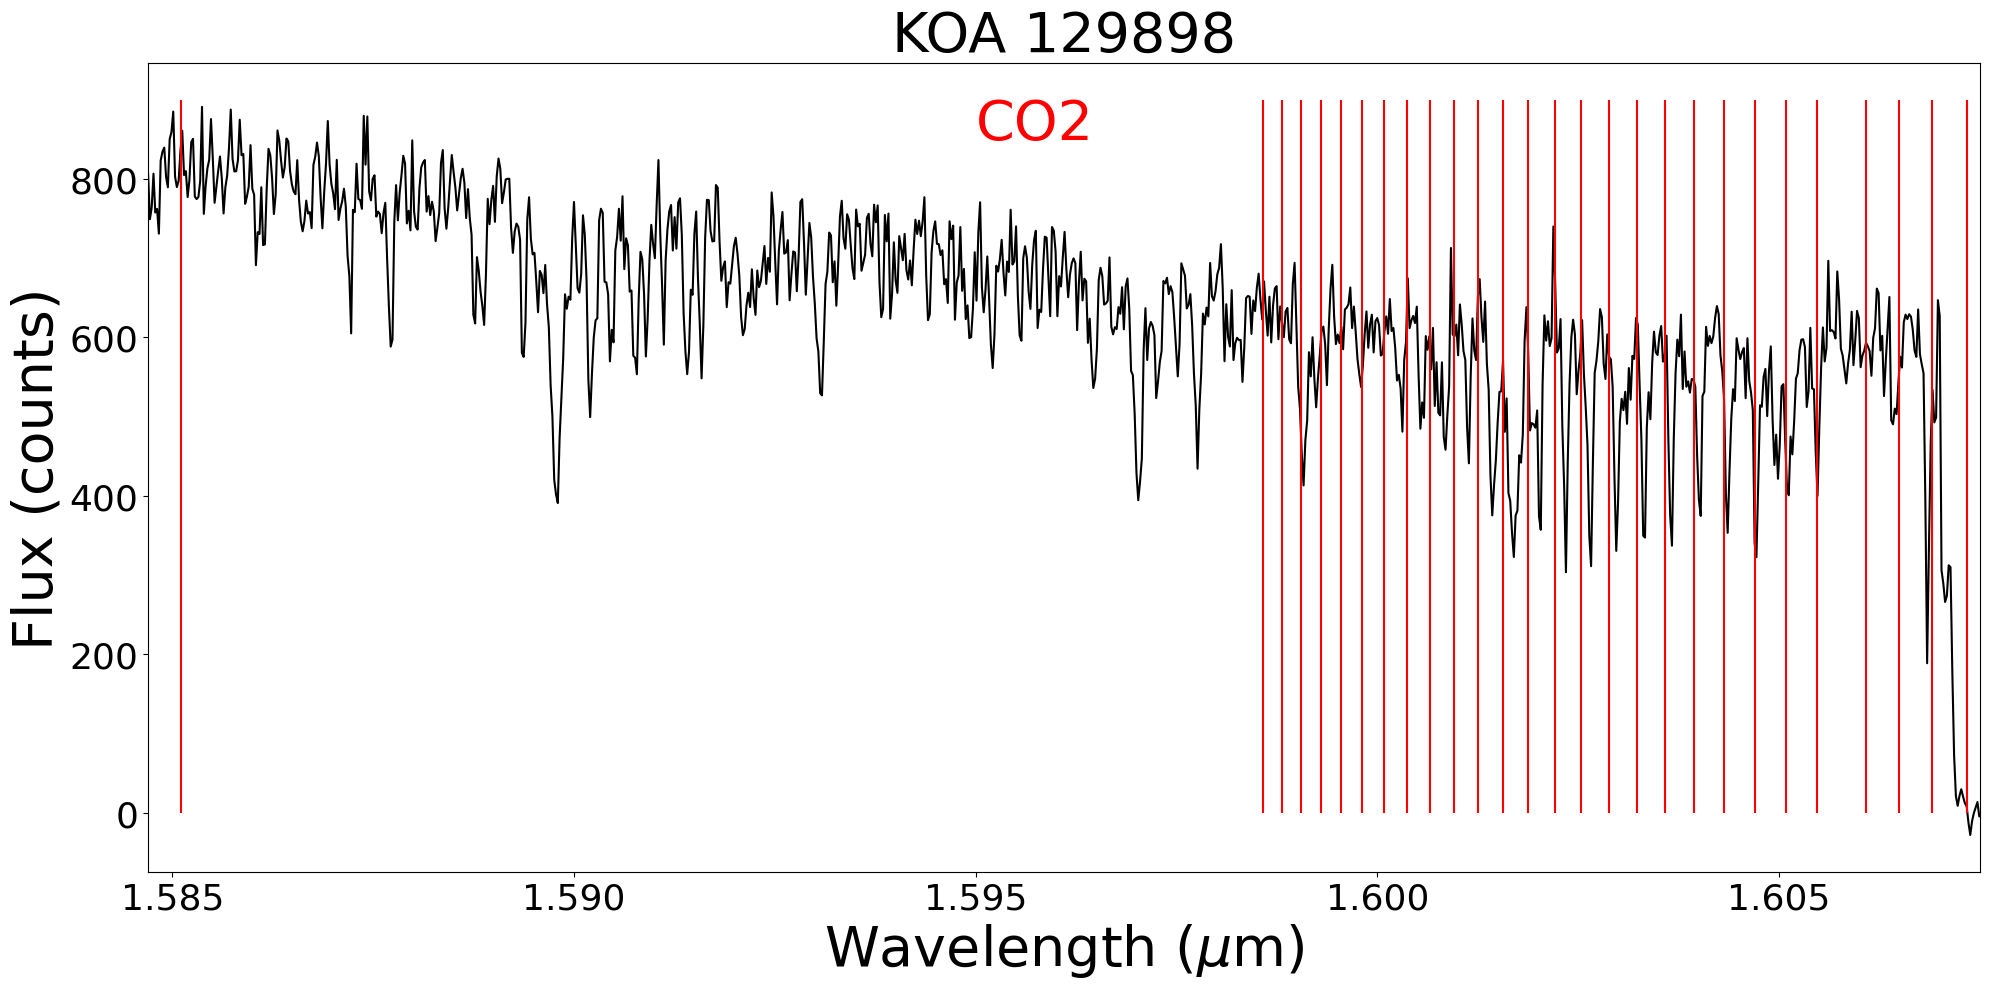

In [578]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(o, ij, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.5847, 1.6075]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['o'], ymin = 0, ymax = 900, color = 'r', label = 'CO2')
plt.text(1.595, 850,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 129898', fontsize = fs) # Giving the plot a title and applying fontsize

plt.tight_layout()
plt.savefig('figs/KOA_129898_CO2.pdf') # Saving the plot
plt.show()

In [579]:
# KOA_130562
fits_file_p = fits.open('/Users/erin/Documents/Projects/KOA_Climate/data/KOA_130562/NIRSPEC/extracted/fitstbl/flux/NS.20000328.42144_48_flux_tbl.fits.gz')

data_class_p = fits_file_p[1] # Get the [1]th element of fits_file
data_p = data_class_p.data # Get the data from data_class

p = data_p['wave (A)'] # Get the wavelength column
kl = data_p['flux (cnts)'] # Get the flux column
p = p / 10000 # Convert the wavelength from Angstroms to microns 

In [580]:
co2 = pd.read_csv('data/C02_1.4_1.7.txt',sep=',') # Reading in the file
co2['p'] = 1/co2['nu']
co2['p'] = co2['p'] * 10**4# centimenters to microns
co2 = co2[co2['sw'] > co2['sw'].quantile(0.99)] # strongest signals only

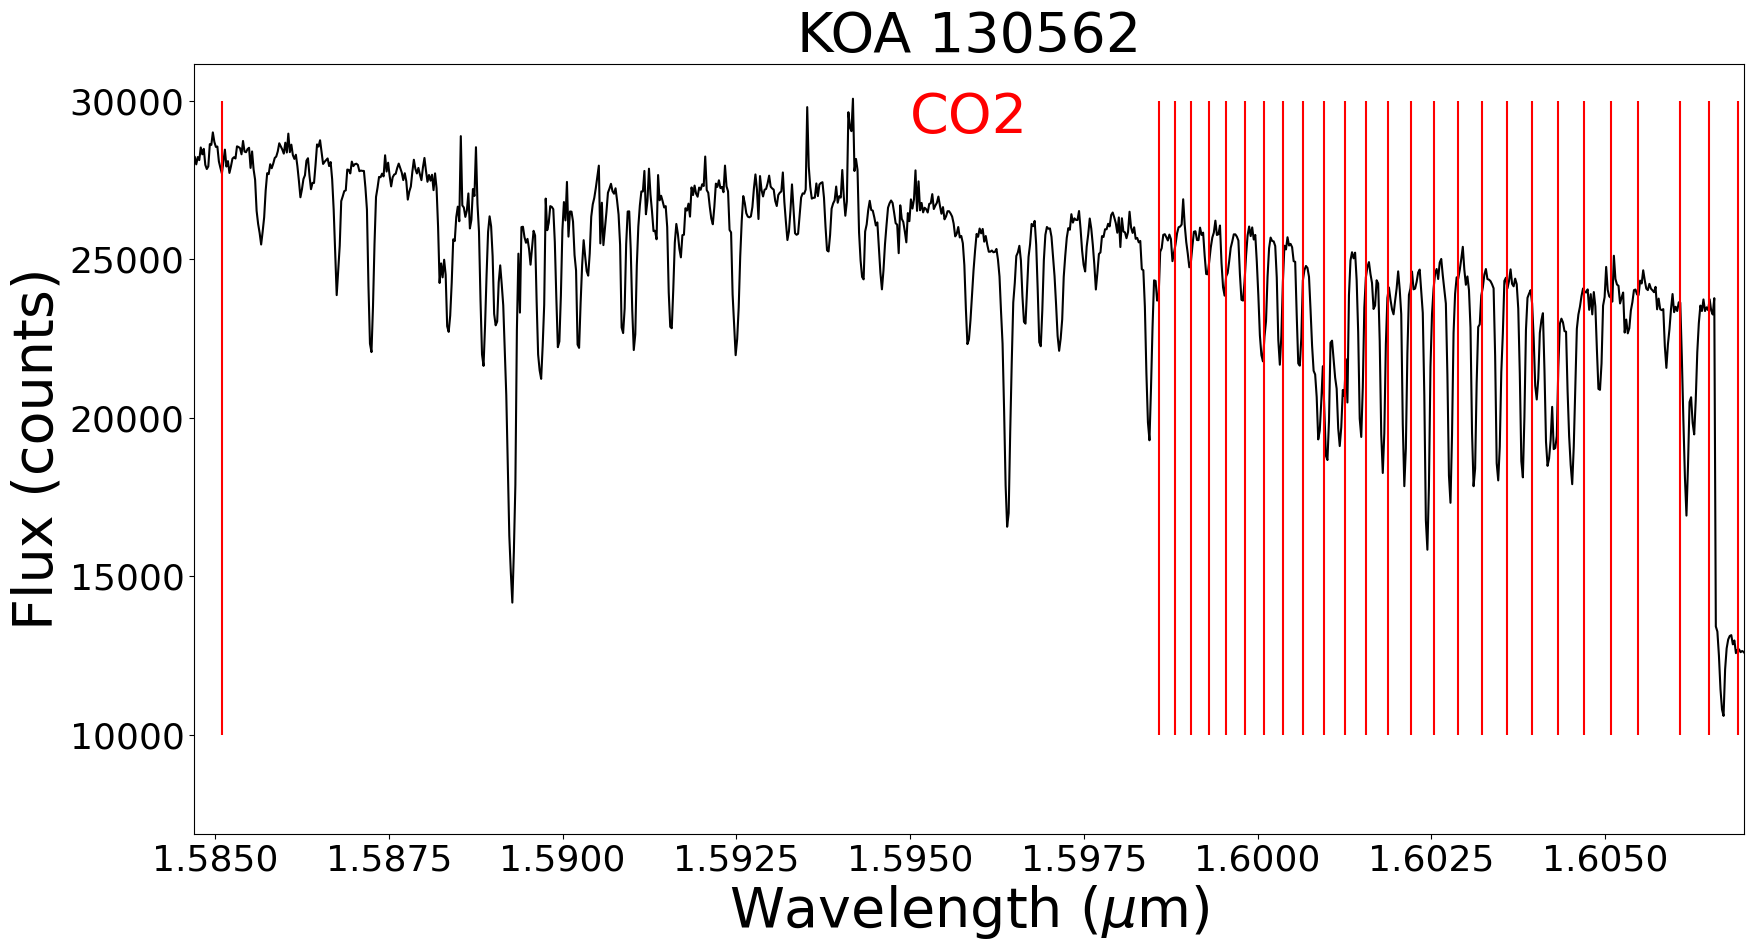

In [581]:
fs = 40 # Fontsize
ts = 26 # Tick size
plt.figure(figsize = (20,10)) # Figure size
plt.plot(p, kl, color = 'k', label = 'data') # plotting wavelength vs. flux and coloring the data

plt.xlim([1.5847, 1.607]) # Limits of the x-axis
plt.xticks(fontsize = ts) # Tick size on the x-axis
plt.yticks(fontsize = ts) # Tick size on the y-axis

plt.vlines(co2['p'], ymin = 10000, ymax = 30000, color = 'r', label = 'CO2')
plt.text(1.595, 29000,'CO2', fontsize=fs, color='r')

plt.xlabel('Wavelength ($\mu$m)', fontsize = fs) # Labelling the x-axis and applying fontsize
plt.ylabel('Flux (counts)', fontsize = fs) # Labelling the y-axis and applying fontsize
plt.title('KOA 130562', fontsize = fs) # Giving the plot a title and applying fontsize

plt.show() # Show the plot